# ДЗ 1. Продажи товара

Проведён анализ продаж товара ASSORTED COLOUR BIRD ORNAMENT по дням, неделям и месяцам. Объектом исследования является изменение количества продаваемых штук в день. Покупки прибавляются, возвраты вычитаются в день оформления.

In [1]:
# Подключение библиотек

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss

## Данные и выбор товара

In [2]:
# Чтение файла и перенос InvoiceDate в формат даты и времени
def load_data(path):
    df = pd.read_csv(path, dtype={'InvoiceNo': str, 'StockCode': str})
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%Y %H:%M')
    return df

# Для наглядности вывод первых трех строк
df = load_data('data/online_retail.csv.gz')
df.head(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom


In [3]:
# Проверка числа пропусков
def check_data(df):
    print('Строк и столбцов:', df.shape)
    return pd.DataFrame({'Тип': df.dtypes, 'Пропуски': df.isna().sum()})

check_data(df)

Строк и столбцов: (541909, 8)


,Тип,Пропуски
InvoiceNo,object,0
StockCode,object,0
Description,object,1454
Quantity,int64,0
InvoiceDate,datetime64[ns],0
UnitPrice,float64,0
CustomerID,float64,135080
Country,object,0


In [4]:
# Просмотр товаров в датасете
df[['StockCode', 'Description']].drop_duplicates().head(10)

,StockCode,Description
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER
1,71053,WHITE METAL LANTERN
2,84406B,CREAM CUPID HEARTS COAT HANGER
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE
4,84029E,RED WOOLLY HOTTIE WHITE HEART.
5,22752,SET 7 BABUSHKA NESTING BOXES
6,21730,GLASS STAR FROSTED T-LIGHT HOLDER
7,22633,HAND WARMER UNION JACK
8,22632,HAND WARMER RED POLKA DOT
9,84879,ASSORTED COLOUR BIRD ORNAMENT


In [5]:
# Отбор покупок и возвратов товара
def get_sales(df, stock_code):
    product = df.loc[df['StockCode'] == stock_code]
    cancelled = product['InvoiceNo'].str.startswith('C')
    purchase = ~cancelled & (product['Quantity'] > 0)
    returned = cancelled & (product['Quantity'] < 0)
    keep = (product['UnitPrice'] > 0) & (purchase | returned)
    sales = product.loc[keep]

    print('Куплено, шт.:', sales.loc[purchase, 'Quantity'].sum())
    returns = sales.loc[returned, 'Quantity']
    print('Строк возврата:', len(returns), '| Всего, шт.:', returns.sum())
    repeats = sales.loc[sales.duplicated(), 'Quantity']
    print('Полных повторов:', len(repeats), '| В них, шт.:', repeats.sum())
    display(product.loc[~keep, ['InvoiceDate', 'Description', 'Quantity', 'UnitPrice']])
    return sales

sales = get_sales(df, '84879')

Куплено, шт.: 36461
Строк возврата: 12 | Всего, шт.: -80
Полных повторов: 13 | В них, шт.: 99


,InvoiceDate,Description,Quantity,UnitPrice
189299,2011-05-13 13:58:00,damaged,-160,0.0


Объём покупок составил 36 461 штуку, объём возвратов - 80 штук. Чистые продажи составили 36 381 штуку. Строка `damaged` на -160 штук с нулевой ценой исключена как складское списание.

В таблице 13 полных повторов на 99 штук. Время относится ко всей накладной и совпадает у разных позиций. Один товар мог быть внесён отдельными строками с одинаковым количеством и ценой. Без номера позиции по выгрузке нельзя отличить такой случай от ошибочного дубликата, поэтому все строки сохранены.

## Календарь продаж

Покупки и возвраты суммируются за каждый день. Из дневных сумм получены продажи за календарный месяц и за неделю. Проведена проверка совпадения общего итога на всех трёх частотах.

In [6]:
def get_product_series(sales, dates):
    daily = sales.groupby(sales['InvoiceDate'].dt.normalize())['Quantity'].sum()
    daily = daily.reindex(dates, fill_value=0)
    return {'День': daily, 'Неделя': daily.resample('W-SUN').sum(),
            'Месяц': daily.resample('MS').sum()}

start, end = df['InvoiceDate'].min(), df['InvoiceDate'].max()
dates = pd.date_range(start.normalize(), end.normalize(), freq='D')
print('Первая и последняя операции:', start, '-', end)
series = get_product_series(sales, dates)
totals = pd.DataFrame({name: s.agg(['size', 'sum']) for name, s in series.items()})
totals.rename(index={'size': 'Периодов', 'sum': 'Чистые продажи, шт.'})

Первая и последняя операции: 2010-12-01 08:26:00 - 2011-12-09 12:50:00


,День,Неделя,Месяц
Периодов,374,54,13
"Чистые продажи, шт.",36381,36381,36381


In [7]:
# Проверка записей магазина и операций с товаром в дни с нулевыми продажами
def check_empty_days(df, sales, daily):
    shop = df.groupby(df['InvoiceDate'].dt.normalize()).size().reindex(daily.index, fill_value=0)
    items = sales.groupby(sales['InvoiceDate'].dt.normalize()).size().reindex(daily.index, fill_value=0)
    groups = {'Нет операций магазина': shop == 0,
              'Есть операции, товар не встречается': (shop > 0) & (items == 0),
              'Покупки и возвраты дали ноль': (items > 0) & (daily == 0)}
    table = {}
    for name, mask in groups.items():
        days = daily.index[mask]
        print(name, '-', len(days))
        by_month = pd.Series(days.strftime('%d'), index=days.to_period('M'))
        table[name] = by_month.groupby(level=0).agg(', '.join)
    return pd.DataFrame(table).fillna('-')

check_empty_days(df, sales, series['День'])

Нет операций магазина - 69
Есть операции, товар не встречается - 5
Покупки и возвраты дали ноль - 0


,Нет операций магазина,"Есть операции, товар не встречается",Покупки и возвраты дали ноль
2010-12,"04, 11, 18, 24, 25, 26, 27, 28, 29, 30, 31","20, 22",-
2011-01,"01, 02, 03, 08, 15, 22, 29",-,-
2011-02,"05, 12, 19, 26",-,-
2011-03,"05, 12, 19, 26",-,-
2011-04,"02, 09, 16, 22, 23, 24, 25, 29, 30",03,-
2011-05,"02, 07, 14, 21, 28, 30",-,-
2011-06,"04, 11, 18, 25",26,-
2011-07,"02, 09, 16, 23, 30",03,-
2011-08,"06, 13, 20, 27, 29",-,-
2011-09,"03, 10, 17, 24",-,-


В течение 5 дней магазин регистрировал другие операции, но покупок и возвратов выбранного товара не было. Ещё за 69 дней нет записей по всему магазину. Дней, когда покупки и возвраты дали в сумме ноль, не оказалось.

Для сравнения продаж используются полные периоды. Ниже срезы `iloc` убирают периоды на границах выгрузки

In [8]:
full = {'День': series['День'].iloc[:-1],
        'Неделя': series['Неделя'].iloc[1:-1],
        'Месяц': series['Месяц'].iloc[:-1]}

## Выбросы и разброс продаж

Для дней, недель и месяцев рассчитаны отдельные границы выбросов. Между квартилями Q1 и Q3 лежат центральные 50% значений. Их разность, IQR = Q3 - Q1. По правилу Тьюки значения ниже Q1 - 1,5 × IQR или выше Q3 + 1,5 × IQR являются выбросами.

Дневной ряд показан дважды. Первый график нужен, чтобы увидеть размер пиков. На втором шкала заканчивается на 550 штуках. В неё помещаются все дни, кроме трёх с продажами выше 1 000 штук для лучшего демонстрирования графика. Эти три дня обозначены треугольниками.

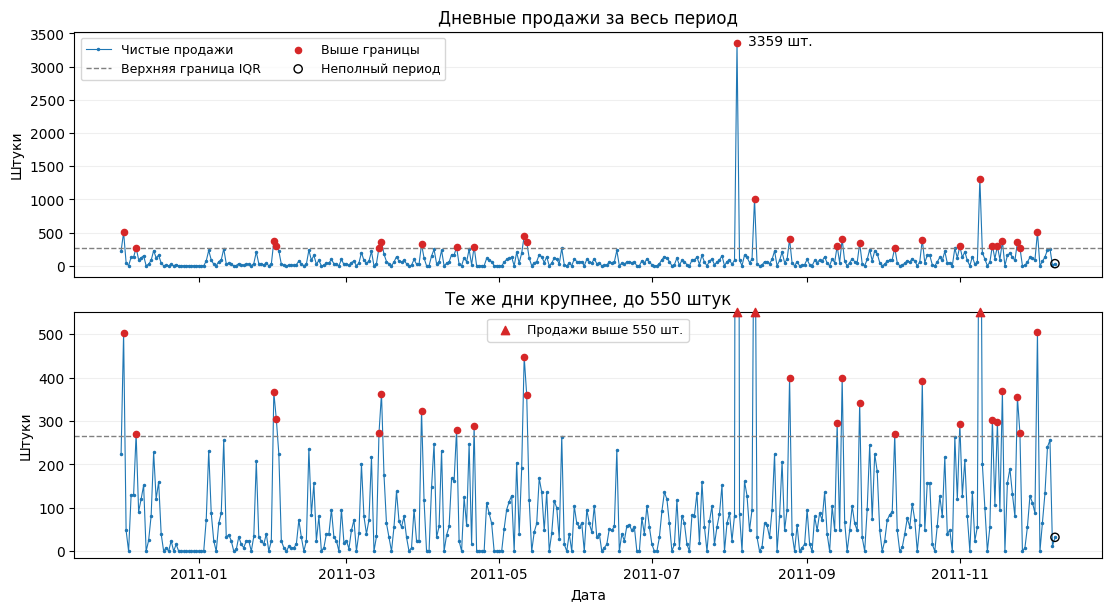

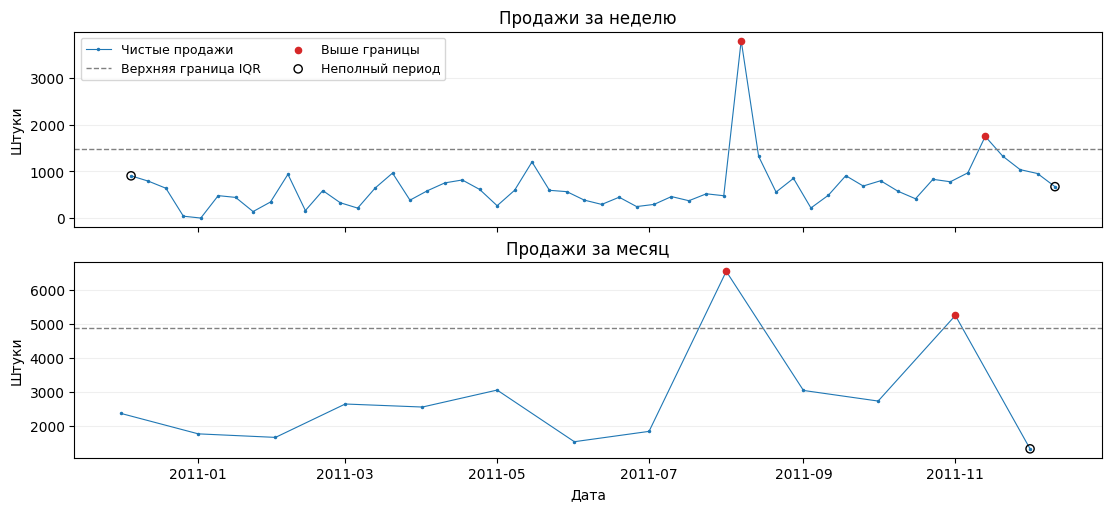

,Период,Полных периодов,Нижняя граница,Верхняя граница,Выбросов,"Доля, %"
0,День,373,-134.00,266.00,27,7.2
1,Неделя,52,-277.75,1476.25,2,3.8
2,Месяц,12,-11.75,4888.25,2,16.7


In [9]:
def find_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < low) | (s > high)], low, high

def draw_sales(ax, name, s, peaks, partial, high):
    ax.plot(s.index, s, '.-', linewidth=0.8, markersize=3, label='Чистые продажи')
    ax.axhline(high, color='grey', linestyle='--', linewidth=1, label='Верхняя граница IQR')
    ax.scatter(peaks.index, peaks, s=20, color='tab:red', zorder=3, label='Выше границы')
    ax.scatter(partial.index, partial, s=35, facecolors='none', edgecolors='black',
               zorder=4, label='Неполный период')
    ax.set(title=name, ylabel='Штуки')
    ax.grid(axis='y', alpha=0.2)

def plot_sales(series, full):
    _, (day_ax, zoom_ax) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout='constrained')
    _, (week_ax, month_ax) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout='constrained')
    axes = {'День': day_ax, 'Неделя': week_ax, 'Месяц': month_ax}
    titles = {'День': 'Дневные продажи за весь период',
              'Неделя': 'Продажи за неделю', 'Месяц': 'Продажи за месяц'}
    rows = []
    for name, s in series.items():
        sample = full[name]
        peaks, low, high = find_outliers(sample)
        partial = s.loc[~s.index.isin(sample.index)]
        draw_sales(axes[name], titles[name], s, peaks, partial, high)
        rows.append([name, len(sample), low, high, len(peaks), round(100 * len(peaks) / len(sample), 1)])

        if name == 'День':
            day_ax.annotate(f'{s.max():.0f} шт.', (s.idxmax(), s.max()),
                            xytext=(8, -2), textcoords='offset points')
            limit = 550
            draw_sales(zoom_ax, 'Те же дни крупнее, до 550 штук', s, peaks, partial, high)
            zoom_ax.set_ylim(-15, limit)
            above = s[s > limit]
            markers = zoom_ax.scatter(above.index, [limit] * len(above), marker='^', color='tab:red',
                                      clip_on=False, zorder=4, label='Продажи выше 550 шт.')
            zoom_ax.legend(handles=[markers], loc='upper center', fontsize=9)

    for ax in [day_ax, week_ax]:
        ax.legend(loc='upper left', ncol=2, fontsize=9)
    for ax in [zoom_ax, month_ax]:
        ax.set_xlabel('Дата')
    plt.show()
    return pd.DataFrame(rows, columns=['Период', 'Полных периодов', 'Нижняя граница',
                                       'Верхняя граница', 'Выбросов', 'Доля, %'])

plot_sales(series, full)

Дневную границу в 266 штук превысили 27 из 373 полных дней (7,2%). Максимум пришёлся на 4 августа - 3 359 штук, из них 2 880 по одной накладной. За границами оказались также две недели из 52 и два месяца из 12.

Для оценки изменения продаж со временем каждый ряд разделён на две половины. Для каждой половины рассчитаны и сопоставлены среднее и стандартное отклонение.

In [10]:
def describe_sales(s):
    mid = len(s) // 2
    return pd.Series({'Среднее': s.mean(), 'Медиана': s.median(), 'Минимум': s.min(),
                      'Максимум': s.max(), 'Станд. отклонение': s.std(),
                      'Среднее, 1-я половина': s.iloc[:mid].mean(),
                      'Среднее, 2-я половина': s.iloc[mid:].mean(),
                      'Станд. откл., 1-я половина': s.iloc[:mid].std(),
                      'Станд. откл., 2-я половина': s.iloc[mid:].std()})

pd.DataFrame({name: describe_sales(s) for name, s in full.items()}).round(1)

,День,Неделя,Месяц
Среднее,97.5,669.3,2920.9
Медиана,56.0,579.0,2604.5
Минимум,0.0,0.0,1540.0
Максимум,3359.0,3800.0,6552.0
Станд. отклонение,209.8,561.1,1512.5
"Среднее, 1-я половина",76.7,517.4,2346.2
"Среднее, 2-я половина",118.1,821.2,3495.7
"Станд. откл., 1-я половина",96.2,293.6,536.3
"Станд. откл., 2-я половина",279.2,712.8,1988.1


Медиана чистых продаж за день - 56 штук, среднее - 97,45. Крупные заказы поднимают среднее. Средний объём продаж в первой половине периода составил 77 штук в день, во второй - 118. Стандартное отклонение выросло с 96 до 279 штук. Крупные заказы во второй половине периода заметно увеличили разброс.

## Тренд и сезонность

Проведена проверка зависимости объёма продаж от дня недели. Сопоставлены медианы понедельников, вторников и остальных дней недели. Рассчитана корреляция с продажами за предыдущий день и с продажами в тот же день одну, две и три недели назад.

In [11]:
def check_week(daily):
    medians = daily.groupby(daily.index.dayofweek).median()
    medians.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
    display(medians.to_frame('Медиана, шт.').T)
    return pd.Series({lag: daily.autocorr(lag) for lag in [1, 7, 14, 21]},
                     name='Автокорреляция по лагам, дни').round(2)

check_week(full['День'])

,Пн,Вт,Ср,Чт,Пт,Сб,Вс
"Медиана, шт.",76.0,76.0,85.0,91.0,48.0,0.0,42.0


1     0.04
7     0.26
14    0.09
21    0.13
Name: Автокорреляция по лагам, дни, dtype: float64

Медиана четверга - 91 штука, воскресенья - 42. По субботам в магазине вообще нет записей. Корреляция с предыдущим днём равна 0,04, а с тем же днём прошлой недели - 0,26. В зарегистрированных продажах явно заметен недельный ритм.

### Разложение дневного ряда

STL делит продажи за день на три части. Тренд показывает общий уровень, сезонная часть - общую прибавку или спад в этот период времени. Остаток - то, что остаётся после вычитания первых двух частей.

- `period=7` задаёт повторение каждые семь дней, что соответствует недельному ритму, который виден в таблице выше.
- `seasonal=53` задаёт окно для сравнения одинаковых дней недели. Это практически весь доступный год. Такое окно позволяет увидеть устойчивые различия между днями недели.
- `trend=29` задаёт окно из 29 последовательных дней. Это примерно один месяц. Так отдельная удачная неделя меньше влияет на оценку общего уровня. Для обоих окон STL требует нечётную длину.


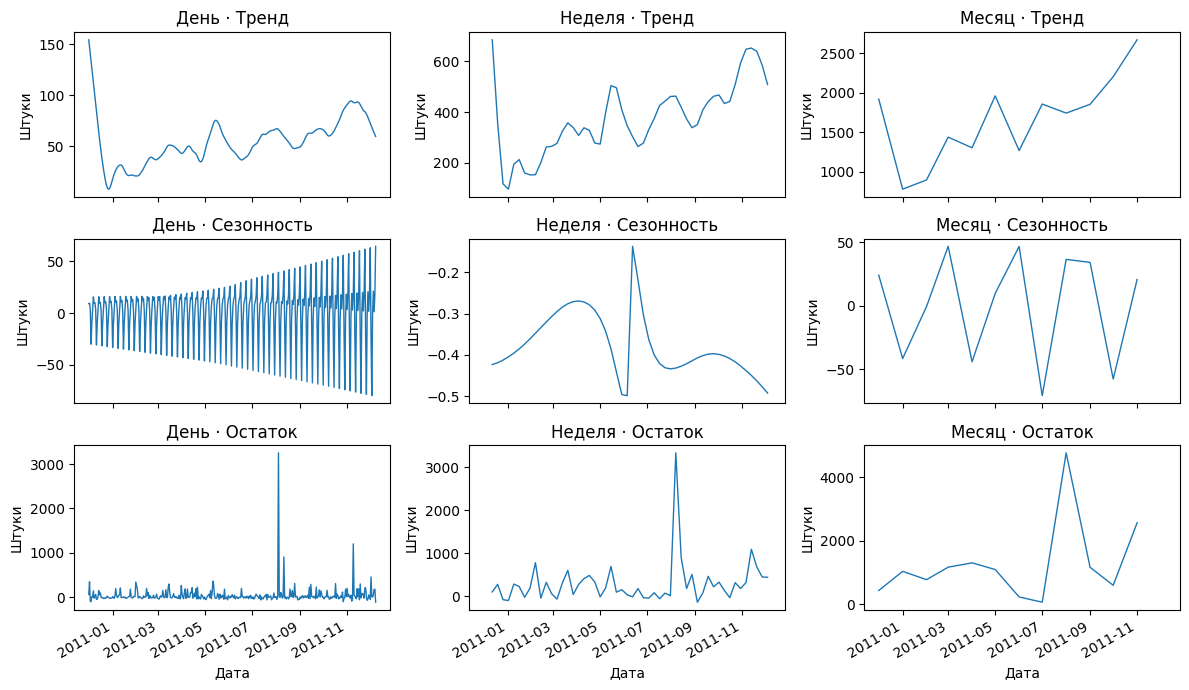

In [12]:
def plot_components(full):
    fit = STL(full['День'], period=7, seasonal=53, trend=29, robust=True).fit()
    daily = pd.DataFrame({'Тренд': fit.trend, 'Сезонность': fit.seasonal, 'Остаток': fit.resid})
    parts = {'День': daily, 'Неделя': daily.resample('W-SUN').sum(),
             'Месяц': daily.resample('MS').sum()}
    fig, axes = plt.subplots(3, 3, figsize=(12, 7), sharex=True)
    for col, (name, table) in enumerate(parts.items()):
        table = table.loc[full[name].index]
        for row, component in enumerate(table):
            ax = axes[row, col]
            ax.plot(table.index, table[component], linewidth=1)
            ax.set_title(name + ' · ' + component)
            ax.set_ylabel('Штуки')
        axes[-1, col].set_xlabel('Дата')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

plot_components(full)

После зимнего спада общий уровень продаж к ноябрю вырос. Самый большой остаток пришёлся на 4 августа. Даже с учётом тренда и обычных продаж по четвергам заказ в этот день был необычно крупным.

На недельных и месячных графиках сложены те же дневные компоненты. За полную неделю подъёмы и спады в разные дни почти компенсируются. Проверить, повторяется ли ноябрьский подъём каждый год, по 12 полным месяцам невозможно.

## Стационарность

Проведена проверка стационарности продаж вокруг постоянного уровня. Значения p-value двух тестов сопоставлены с порогом 0,05.

- У **ADF** малое p даёт основания отвергнуть гипотезу о единичном корне характеристического уравнения временного ряда. При единичном корне случайный скачок может надолго изменить уровень ряда.
- У **KPSS** малое p даёт основания отвергнуть стационарность вокруг постоянного уровня.

Оба теста выполнены с константой. В KPSS для дневного ряда учитывается связь между днями на расстоянии до недели (7 лагов). Для недель и месяцев используется один соседний период. В месячном ADF подбор также ограничен одним лагом, поскольку есть всего 12 наблюдений.

In [13]:
def stationarity(s, name):
    maxlag = 1 if name == 'Месяц' else None
    adf_p = adfuller(s, maxlag=maxlag, regression='c')[1]
    lags = 7 if name == 'День' else 1
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', InterpolationWarning)
        kpss_p = kpss(s, regression='c', nlags=lags)[1]
    return {'Точек': len(s), 'p ADF': f'{adf_p:.3g}', 'p KPSS': f'{kpss_p:.3f}'}

pd.DataFrame({name: stationarity(s, name) for name, s in full.items()}).T

,Точек,p ADF,p KPSS
День,373,2.98e-06,0.028
Неделя,52,4.82e-06,0.032
Месяц,12,0.0844,0.077


Для дней и недель ADF даёт p меньше 0,05, при этом у KPSS тоже малые p - 0,028 и 0,032. ADF отвергает гипотезу о единичном корне. KPSS отвергает стационарность вокруг постоянного среднего. Для месячных сумм оба p выше 0,05, но нужно учитывать, что по 12 точкам однозначный вывод сделать трудно.

Для уменьшения влияния недельного ритма выполнено преобразование ряда. Для каждого дня рассчитан логарифм от количества плюс один. Затем вычтено такое же значение за тот же день предыдущей недели. Логарифм уменьшает влияние крупных заказов и допускает нули.

Для недель и месяцев из каждой суммы вычтена сумма предыдущего периода, после чего оба теста выполнены повторно.

In [14]:
def transform_sales(full):
    daily = full['День']
    log_daily = np.sign(daily) * np.log1p(daily.abs())
    return {'День': log_daily.diff(7).dropna(),
            'Неделя': full['Неделя'].diff().dropna(),
            'Месяц': full['Месяц'].diff().dropna()}

changed = transform_sales(full)
pd.DataFrame({name: stationarity(s, name) for name, s in changed.items()}).T

,Точек,p ADF,p KPSS
День,366,1.12e-13,0.100
Неделя,51,1.95e-12,0.100
Месяц,11,6.18e-06,0.100


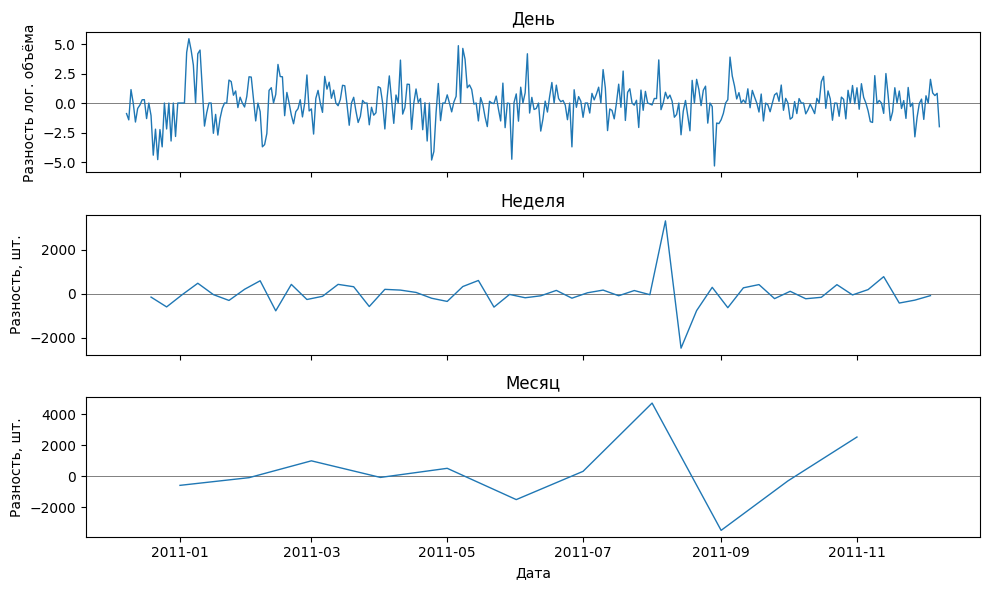

,Пн,Вт,Ср,Чт,Пт,Сб,Вс
Стандартное отклонение разностей,2.09,1.53,1.61,1.4,1.51,0.0,1.9


In [15]:
# Построение графиков после преобразований
def plot_changes(changed):
    fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    for ax, (name, s) in zip(axes, changed.items()):
        ax.axhline(0, color='grey', linewidth=0.7)
        ax.plot(s.index, s, linewidth=1)
        unit = 'Разность лог. объёма' if name == 'День' else 'Разность, шт.'
        ax.set(title=name, ylabel=unit)
    axes[-1].set_xlabel('Дата')
    fig.tight_layout()
    plt.show()

plot_changes(changed)

# Сравнение разброса после преобразования по дням недели
daily_changes = changed['День']
spread = daily_changes.groupby(daily_changes.index.dayofweek).std()
spread.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
spread.to_frame('Стандартное отклонение разностей').T.round(2)

После преобразования у всех трёх рядов p ADF ниже 0,05. Для KPSS таблица заканчивается на 0,10, поэтому результат 0,100 интерпретируется как p ≥ 0,10. Тесты согласуются со стационарностью по уровню. При этом у дневных разностей разброс зависит от дня недели. По субботам разность всегда равна нулю, а в остальные дни стандартное отклонение составляет от 1,40 до 2,09. Для месячного ряда вывод предварительный. После преобразования осталось 11 точек.

Для дальнейшего прогнозирования рекомендуется начать с дневного ряда. В нём можно учесть день недели и проверить, насколько ошибается прогноз в дни крупных заказов.